# Learning CNNs with MNIST and LeNet-5

**Goal** · Trace how a handwritten digit becomes ten class scores. We’ll compute one filter response by hand, follow the shape of a tensor through the network, then train the model and inspect its feature maps.

MNIST is a good first dataset for this experiment. It has ten familiar classes, small single-channel images, and the same benchmark lets us follow the examples in the 1998 paper. Start with Sections 1–3. Section 4 trains a baseline you can revisit as you change the architecture.

[LeCun, Bottou, Bengio & Haffner, *Gradient-Based Learning Applied to Document Recognition* (1998), Sections II-B and III, especially Figure 2](https://leon.bottou.org/publications/pdf/ieee-1998.pdf)

## Setup

**Colab** · Choose **File → Upload notebook**, then run the cells in order. A CPU is enough for this project. [Colab upload instructions](https://research.google.com/colaboratory/faq.html)

**Local Jupyter on Windows** · Use a Python 3.12 environment. From the project folder, run these commands in PowerShell, then open the notebook in JupyterLab.

```powershell
py -3.12 -m venv .venv
.\.venv\Scripts\python.exe -m pip install jupyterlab matplotlib
.\.venv\Scripts\python.exe -m pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu
.\.venv\Scripts\python.exe -m jupyterlab
```

The first dataset cell downloads MNIST into `data/` relative to the notebook’s working directory. [PyTorch installation](https://pytorch.org/get-started/locally/) · [Jupyter installation](https://jupyter.org/install)

In [ ]:
from collections import OrderedDict #Ci permette di costruire una sequenza di strati con nomi come c1, s2 e c3. Potremo così osservare l’output di ciascuno strato.
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
DATA_DIR = Path("data")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)

print(f"PyTorch {torch.__version__} | device {device}")

PyTorch 2.15.0+cpu | device cpu


## 1. Look at the input

MNIST’s official split has 60,000 training images and 10,000 test images. We set aside 5,000 images from the training split for validation. Use validation to compare experiments and save the official test set for the final check.

Each image is 28 × 28. Add two background pixels to each side to get LeNet-5’s 32 × 32 input. `ToTensor` produces a floating-point tensor in `[0, 1]` with shape **channels × height × width**. A data loader adds a batch dimension at the front. [Torchvision MNIST documentation](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html)

100.0%
100.0%
100.0%
100.0%


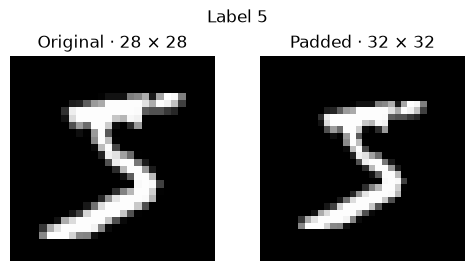

Training images: 55,000
Validation images: 5,000
Image tensor (C, H, W): (1, 32, 32)


In [ ]:
preprocess = transforms.Compose([
    transforms.Pad(2, fill=0), #aggiunge due pixel neri su ciascun lato
    transforms.ToTensor(), #converte l’immagine in un tensore PyTorch
])
mnist = datasets.MNIST(DATA_DIR, train=True, transform=preprocess, download=True)
train_set, val_set = random_split(
    mnist, [55_000, 5_000], generator=torch.Generator().manual_seed(SEED)
)

raw_image = mnist.data[0]
image, label = mnist[0]
assert image.shape == (1, 32, 32) #verifica che la forma sia quella attesa. Se è diversa, la cella si ferma con un errore.
torch.testing.assert_close(image[0, 2:-2, 2:-2], raw_image.float() / 255)

fig, axes = plt.subplots(1, 2, figsize=(5, 2.6), layout="constrained")
axes[0].imshow(raw_image, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[0].set_title("Original · 28 × 28")
axes[1].imshow(image[0], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[1].set_title("Padded · 32 × 32")
for ax in axes:
    ax.set_axis_off()
fig.suptitle(f"Label {label}")
plt.show()

print(f"Training images: {len(train_set):,}")
print(f"Validation images: {len(val_set):,}")
print(f"Image tensor (C, H, W): {tuple(image.shape)}")

## 2. Slide one filter over the digit

At each position, multiply a 5 × 5 patch by the filter weights element by element, sum the products, and add a bias. Using the **same weights and bias** at every position is called weight sharing. The grid of responses is a **feature map**.

The filter below responds to horizontal changes in brightness. It’s fixed so we can see what the weights do. The network will learn its own filters. Try predicting the sign of the response at the left and right edges of a white stroke.

Response at (12, 12): 0.426


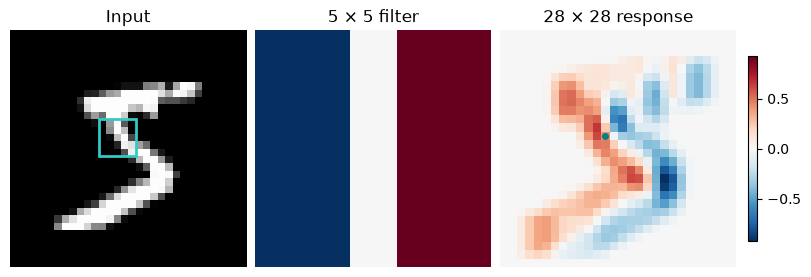

In [3]:
# Each row compares pixels to the left and right of the center column.
kernel = torch.tensor([[-1., -1., 0., 1., 1.]]).repeat(5, 1) / 10
# Input is [batch, channels, height, width].
# Weight is [output channels, input channels, height, width].
response = F.conv2d(image.unsqueeze(0), kernel[None, None])[0, 0]

row, col = 12, 12
patch = image[0, row:row + 5, col:col + 5]
manual_response = (patch * kernel).sum()  # Zero bias for this example.
torch.testing.assert_close(manual_response, response[row, col], atol=1e-6, rtol=1e-5)
print(f"Response at ({row}, {col}): {manual_response.item():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(8, 2.7), layout="constrained")
axes[0].imshow(image[0], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[0].add_patch(
    Rectangle((col - 0.5, row - 0.5), 5, 5, fill=False, edgecolor="#33c9c5", linewidth=2)
)
axes[0].set_title("Input")
axes[1].imshow(kernel, cmap="RdBu_r", vmin=-0.1, vmax=0.1, interpolation="nearest")
axes[1].set_title("5 × 5 filter")
scale = max(response.abs().max().item(), 1e-6)
im = axes[2].imshow(
    response, cmap="RdBu_r", vmin=-scale, vmax=scale, interpolation="nearest"
)
axes[2].plot(col, row, "o", color="#008282", markersize=4)
axes[2].set_title("28 × 28 response")
fig.colorbar(im, ax=axes[2], shrink=0.75)
for ax in axes:
    ax.set_axis_off()
plt.show()

## 3. Follow LeNet-5’s layer shapes

A 5 × 5 convolution with stride 1 and padding set to 0 shrinks each spatial dimension by four. A 2 × 2 average pool with stride 2 halves these even spatial dimensions. A filter in C3 combines information across the six input channels and produces one output map.

| Stage | Operation | Output per image |
| --- | --- | --- |
| Input | Add a two-pixel border | 1 × 32 × 32 |
| C1 | 5 × 5 convolution, 6 filters | 6 × 28 × 28 |
| S2 | 2 × 2 average pooling | 6 × 14 × 14 |
| C3 | 5 × 5 convolution, 16 filters | 16 × 10 × 10 |
| S4 | 2 × 2 average pooling | 16 × 5 × 5 |
| C5 | 5 × 5 convolution, 120 filters | 120 × 1 × 1 |
| Flatten | Keep the batch dimension | 120 |
| F6 | Fully connected layer | 84 |
| Output | Linear class scores (logits) | 10 |

C5 has a single spatial position because its filter covers the whole 5 × 5 input map. In the original network, C3 used a subset of the input channels for each filter, S2 and S4 learned a scale and bias per channel and applied a nonlinearity, and the squashing function was a scaled tanh. The original output layer scored distances to class prototypes. This implementation uses fully connected channel mixing in C3, fixed average pooling, ordinary tanh, and a linear output trained with cross-entropy. We also use the tensor transform above for pixel scaling. [Original paper, Figure 2 and Section II-B](https://leon.bottou.org/publications/pdf/ieee-1998.pdf#page=7)

In [4]:
class LeNetInspired(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(OrderedDict([
            ("c1", nn.Conv2d(1, 6, kernel_size=5)),
            ("act1", nn.Tanh()),
            ("s2", nn.AvgPool2d(kernel_size=2, stride=2)), #kernel_size=2 gives you a 2 × 2 window, and stride=2 moves that window two pixels at a time horizontally and vertically.
            ("c3", nn.Conv2d(6, 16, kernel_size=5)),
            ("act3", nn.Tanh()),
            ("s4", nn.AvgPool2d(kernel_size=2, stride=2)),
            ("c5", nn.Conv2d(16, 120, kernel_size=5)),
            ("act5", nn.Tanh()),
            ("flatten", nn.Flatten(start_dim=1)),
            ("f6", nn.Linear(120, 84)),
            ("act6", nn.Tanh()),
            ("output", nn.Linear(84, 10)),
        ]))

    def forward(self, images):
        return self.layers(images)

In [5]:
expected_shapes = {
    "c1": (6, 28, 28),
    "s2": (6, 14, 14),
    "c3": (16, 10, 10),
    "s4": (16, 5, 5),
    "c5": (120, 1, 1),
    "flatten": (120,),
    "f6": (84,),
    "output": (10,),
}

demo_model = LeNetInspired().eval()
demo_batch = torch.stack([mnist[index][0] for index in range(4)])
print(f"{'input':>7}  {tuple(demo_batch.shape)}")
with torch.inference_mode():
    activations = demo_batch
    for name, layer in demo_model.layers.named_children():
        activations = layer(activations)
        if name in expected_shapes:
            assert tuple(activations.shape) == (len(demo_batch), *expected_shapes[name])
            print(f"{name:>7}  {tuple(activations.shape)}")
    torch.testing.assert_close(activations, demo_model(demo_batch))

print(f"Trainable parameters: {sum(p.numel() for p in demo_model.parameters()):,}")

  input  (4, 1, 32, 32)
     c1  (4, 6, 28, 28)
     s2  (4, 6, 14, 14)
     c3  (4, 16, 10, 10)
     s4  (4, 16, 5, 5)
     c5  (4, 120, 1, 1)
flatten  (4, 120)
     f6  (4, 84)
 output  (4, 10)
Trainable parameters: 61,706


## 4. Train a baseline

In each minibatch, the model predicts ten logits per image. Cross-entropy compares the logits with the true digit labels. Backpropagation computes a gradient for each trainable weight, and Adam updates the weights. `CrossEntropyLoss` takes the raw logits and the integer class labels.

An **epoch** is one pass through the training set. After each epoch, measure loss and accuracy on the validation set with weight updates disabled. Set `EPOCHS = 1` for a shorter first run.

In [6]:
loss_fn = nn.CrossEntropyLoss()


def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
    return total_loss / len(loader.dataset)


@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += loss_fn(logits, labels).item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
    examples = len(loader.dataset)
    return total_loss / examples, correct / examples

In [7]:
EPOCHS = 3
LEARNING_RATE = 1e-3

torch.manual_seed(SEED)
train_loader = DataLoader(
    train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, num_workers=0)

model = LeNetInspired().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = []

for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, optimizer)
    val_loss, val_accuracy = evaluate(model, val_loader)
    history.append((epoch, train_loss, val_loss, val_accuracy))
    print(
        f"Epoch {epoch:>2} | train loss {train_loss:.4f} | "
        f"validation loss {val_loss:.4f} | validation accuracy {val_accuracy:.1%}",
        flush=True,
    )

Epoch  1 | train loss 0.4061 | validation loss 0.1776 | validation accuracy 94.6%
Epoch  2 | train loss 0.1208 | validation loss 0.1046 | validation accuracy 96.7%
Epoch  3 | train loss 0.0796 | validation loss 0.0790 | validation accuracy 97.6%


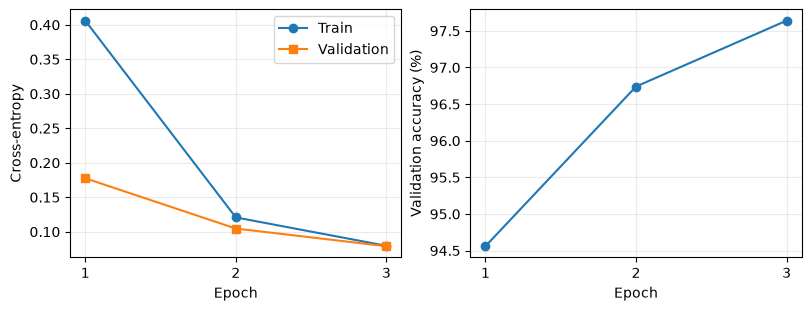

In [8]:
epochs, train_losses, val_losses, val_accuracies = zip(*history)
fig, (loss_ax, accuracy_ax) = plt.subplots(1, 2, figsize=(8, 3), layout="constrained")
loss_ax.plot(epochs, train_losses, "o-", label="Train")
loss_ax.plot(epochs, val_losses, "s-", label="Validation")
loss_ax.set(xlabel="Epoch", ylabel="Cross-entropy", xticks=epochs)
loss_ax.legend()
accuracy_ax.plot(epochs, [100 * accuracy for accuracy in val_accuracies], "o-")
accuracy_ax.set(xlabel="Epoch", ylabel="Validation accuracy (%)", xticks=epochs)
for ax in (loss_ax, accuracy_ax):
    ax.grid(alpha=0.25)
plt.show()

## 5. Inspect a prediction and the learned feature maps

For one validation digit, display the six C1 maps after tanh and the same six channels after pooling. Each column follows one channel. Change `EXAMPLE` to compare straight strokes, curves, and loops. Look for which responses survive averaging.

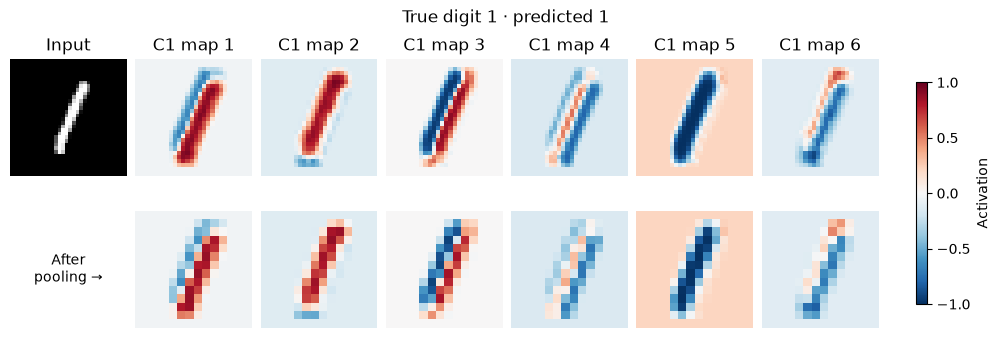

In [17]:
EXAMPLE = 0
example, true_label = val_set[EXAMPLE]
example_batch = example.unsqueeze(0).to(device)

model.eval()
with torch.inference_mode():
    c1_maps = model.layers.act1(model.layers.c1(example_batch))
    s2_maps = model.layers.s2(c1_maps)
    prediction = model(example_batch).argmax(dim=1).item()

fig, axes = plt.subplots(2, 7, figsize=(10, 3.4), layout="constrained")
axes[0, 0].imshow(example[0], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[0, 0].set_title("Input")
axes[1, 0].text(0.5, 0.5, "After\npooling →", ha="center", va="center")
for map_index in range(6):
    for row, maps in enumerate((c1_maps, s2_maps)):
        im = axes[row, map_index + 1].imshow(
            maps[0, map_index].cpu(), cmap="RdBu_r",
            vmin=-1, vmax=1, interpolation="nearest",
        )
    axes[0, map_index + 1].set_title(f"C1 map {map_index + 1}")
for ax in axes.flat:
    ax.set_axis_off()
fig.colorbar(im, ax=list(axes[:, 1:].flat), shrink=0.75, label="Activation")
fig.suptitle(f"True digit {true_label} · predicted {prediction}")
plt.show()

## 6. Change one thing

Predict what will happen if S2 and S4 keep the **largest** value in each 2 × 2 window. Record the baseline’s validation loss and accuracy, replace both `AvgPool2d` layers with `MaxPool2d`, and rerun Sections 3–5 with the same settings and seed. Compare validation accuracy and the pooled maps for the same digit. Which responses changed most?

Once you’ve picked your model, set `RUN_TEST = True` in the next cell and run it for a final score on the official test split.

In [11]:
RUN_TEST = True

if RUN_TEST:
    test_set = datasets.MNIST(DATA_DIR, train=False, transform=preprocess)
    test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, num_workers=0)
    test_loss, test_accuracy = evaluate(model, test_loader)
    print(f"Test loss {test_loss:.4f} | test accuracy {test_accuracy:.1%}")
else:
    print("Test evaluation is off. Use the validation results for experiments.")

Test loss 0.0721 | test accuracy 97.9%
